In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# **`Task 1: Exploratory Data Analysis (EDA):`**

**1.	Load the dataset and perform basic data exploration.**



In [55]:
df = pd.read_csv('wine.csv')

In [56]:
df.shape

(178, 14)

In [57]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Type             178 non-null    int64  
 1   Alcohol          178 non-null    float64
 2   Malic            178 non-null    float64
 3   Ash              178 non-null    float64
 4   Alcalinity       178 non-null    float64
 5   Magnesium        178 non-null    int64  
 6   Phenols          178 non-null    float64
 7   Flavanoids       178 non-null    float64
 8   Nonflavanoids    178 non-null    float64
 9   Proanthocyanins  178 non-null    float64
 10  Color            178 non-null    float64
 11  Hue              178 non-null    float64
 12  Dilution         178 non-null    float64
 13  Proline          178 non-null    int64  
dtypes: float64(11), int64(3)
memory usage: 19.6 KB


In [58]:
df.head()

,Type,Alcohol,Malic,Ash,Alcalinity,Magnesium,Phenols,Flavanoids,Nonflavanoids,Proanthocyanins,Color,Hue,Dilution,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [59]:
df.isnull().sum()

,0
Type,0
Alcohol,0
Malic,0
Ash,0
Alcalinity,0
Magnesium,0
Phenols,0
Flavanoids,0
Nonflavanoids,0
Proanthocyanins,0


In [60]:
df.duplicated().sum()

np.int64(0)

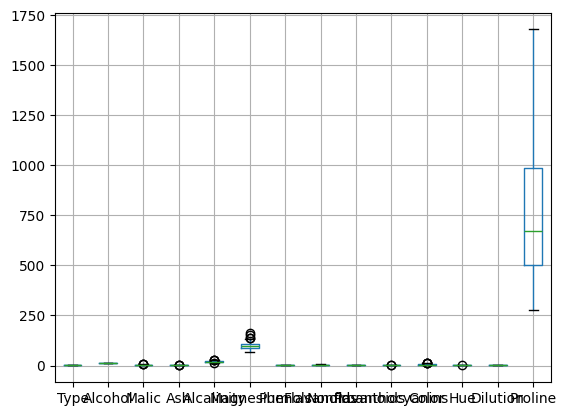

In [61]:
df.boxplot()
plt.show()

In [62]:
def outlier_capping(df, column):
  Q1 = df[column].quantile(0.25)
  Q3 = df[column].quantile(0.75)
  IQR = Q3 - Q1
  lower_extreme = Q1 - 1.5*IQR
  upper_extreme = Q3 + 1.5*IQR
  df[column] = df[column].apply(lambda x: lower_extreme if x<lower_extreme else upper_extreme if x>upper_extreme else x)
for col in df.select_dtypes(['int', 'float']).columns:
  outlier_capping(df, col)

**2.	Examine the distribution of features using histograms, box plots, or density plots.**


Histogram
---

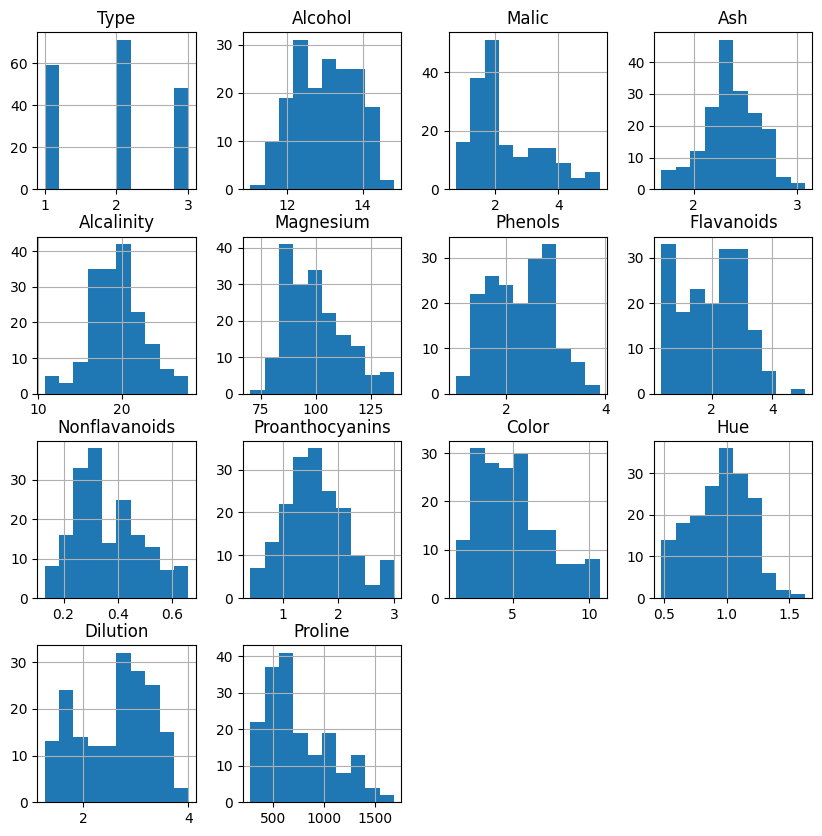

In [63]:
df.hist(figsize=(10,10))
plt.show()

Boxplot
---

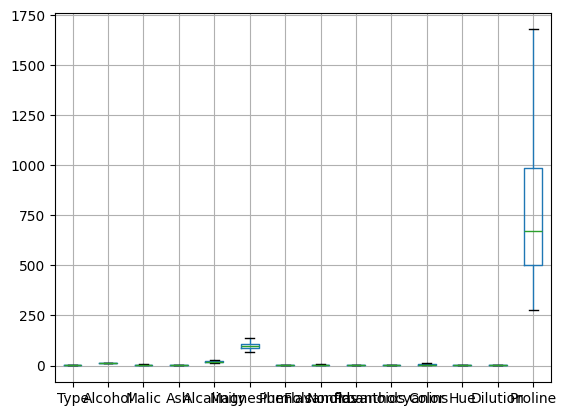

In [64]:
df.boxplot()
plt.show()

Density plot
---

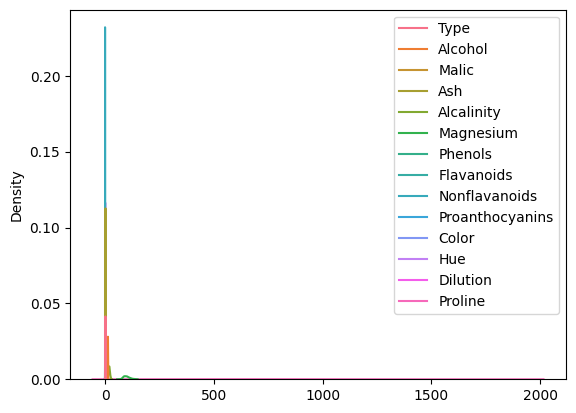

In [65]:
sns.kdeplot(data=df)
plt.show()

**3.	Investigate correlations between features to understand relationships within the data.**

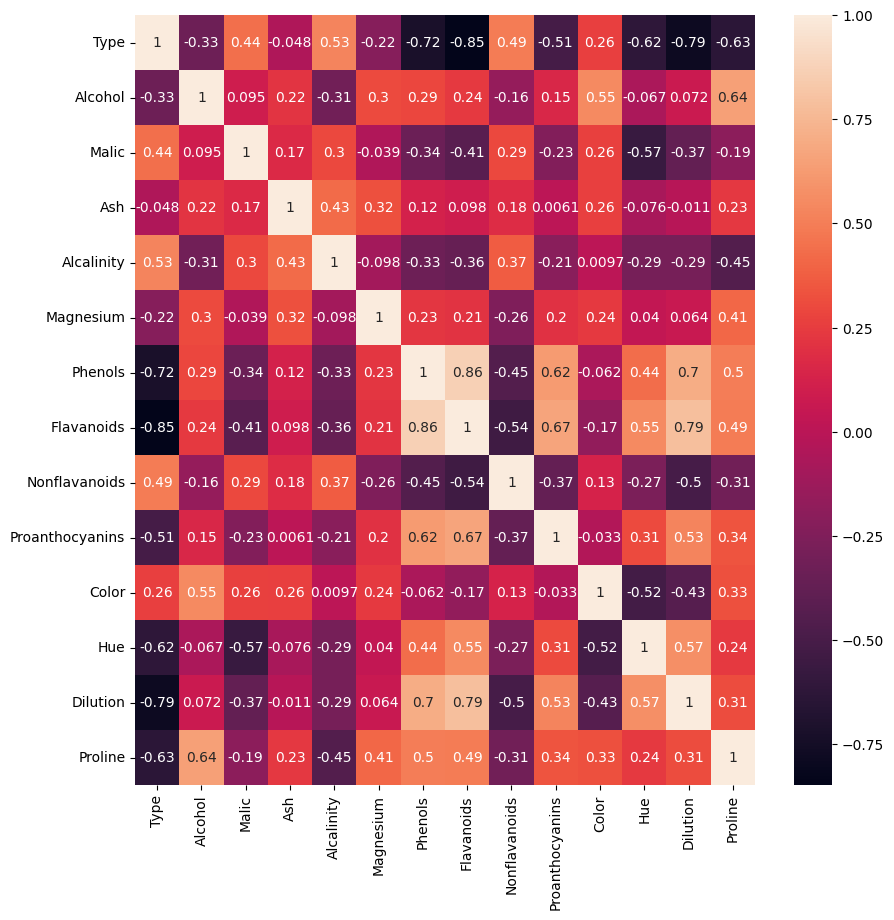

In [66]:
plt.figure(figsize=(10,10))
sns.heatmap(df.corr(), annot=True)
plt.show()

Explanation:
---

First, I loaded wine datset and performed EDA(checked for missing values, duplicated rows and outliers). and visualize the features distribution using histogram, box plots and density plot. And finally for understanding relationships within the data, i used correlation matrix.

# **`Task 2: Dimensionality Reduction with PCA:`**


**1.	Standardize the features to ensure they have a mean of 0 and a standard deviation of Implement PCA to reduce the dimensionality of the dataset.**



In [67]:
target = df[['Type']]
features = df.drop(columns=['Type'])

In [68]:
x_train, x_test, y_train, y_test = train_test_split(features, target, train_size=0.8, random_state=50, stratify=target)
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(142, 13)
(36, 13)
(142, 1)
(36, 1)


In [69]:
std_sca = StandardScaler()
features_std = std_sca.fit_transform(features)

In [70]:
print(f"Mean: {features_std.mean():.2f}")
print(f"Standard Deviation: {features_std.std():.2f}")


Mean: -0.00
Standard Deviation: 1.00


**2.	Determine the optimal number of principal components using techniques like scree plot or cumulative explained variance.**


In [71]:
pca = PCA()
pca.fit(features_std)

PCA()

In [72]:
#explained variance ratio
explained_variance_ratio = pca.explained_variance_ratio_
print(explained_variance_ratio)

[0.36475803 0.19609775 0.10911182 0.07062378 0.06296983 0.04815067
 0.04031504 0.02744533 0.02232516 0.01931106 0.01755433 0.01326634
 0.00807088]


In [73]:
cum_var = np.cumsum(explained_variance_ratio)
print(cum_var)

[0.36475803 0.56085577 0.66996759 0.74059137 0.8035612  0.85171187
 0.89202691 0.91947224 0.9417974  0.96110846 0.97866279 0.99192912
 1.        ]


Scree Plot
---

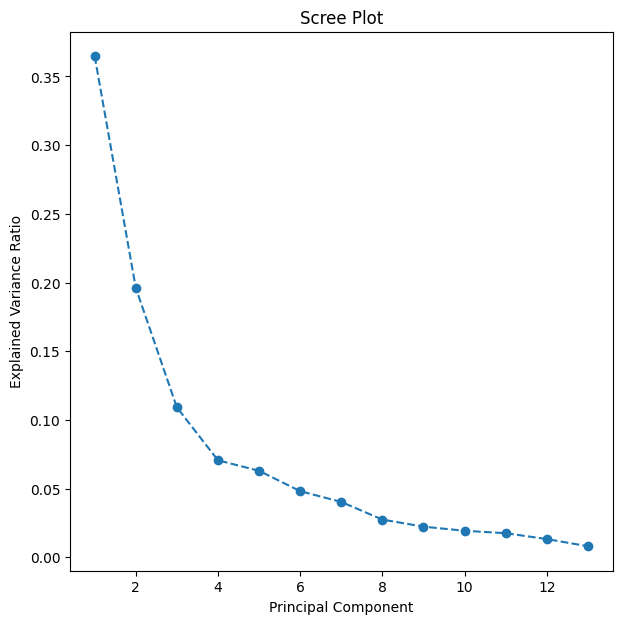

In [74]:
plt.figure(figsize=(7,7))
plt.plot(range(1, len(explained_variance_ratio)+1), explained_variance_ratio, marker='o', linestyle='--')
plt.title('Scree Plot')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.show()

Cumulative explained variance
---

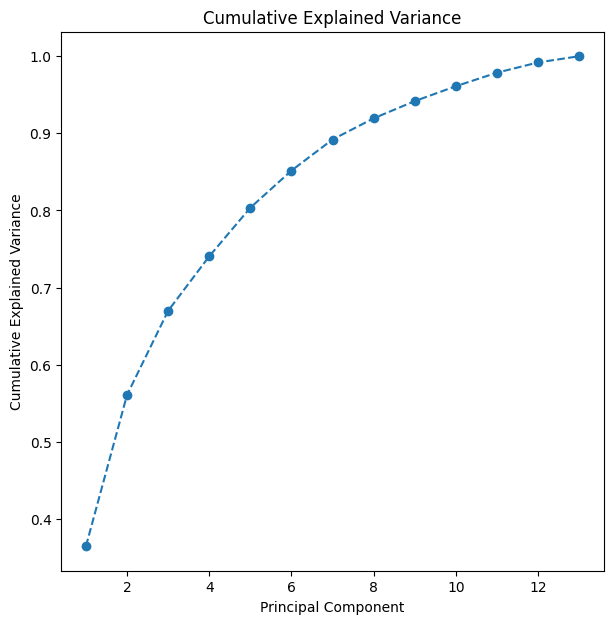

In [75]:
plt.figure(figsize=(7,7))
plt.plot(range(1, len(cum_var)+1), cum_var, marker='o', linestyle='--')
plt.title('Cumulative Explained Variance')
plt.xlabel('Principal Component')
plt.ylabel('Cumulative Explained Variance')
plt.show()


**3.	Transform the original dataset into the principal components.**


In [76]:
pca = PCA(n_components=10)
pca.fit_transform(features_std)

array([[ 3.35814747,  1.52022185, -0.12637492, ...,  0.01918672,
        -0.6892566 , -1.03120871],
       [ 2.22921481, -0.33326137, -2.04283756, ...,  0.9916492 ,
         0.37966369, -0.20878677],
       [ 2.54005743,  1.03695315,  1.01884481, ..., -0.46440095,
         1.16475457, -0.13653812],
       ...,
       [-2.67116907,  2.86530059, -0.97512583, ...,  0.01348408,
        -0.02068873,  0.26726251],
       [-2.37160346,  2.39380794, -0.56148477, ...,  0.35102538,
        -0.08649189, -0.49536603],
       [-3.22745394,  2.80053456,  1.03090733, ..., -0.2033248 ,
        -0.72139851,  0.1784193 ]])

Explanation:
---

I first separated the dataset into features and target because PCA should be applied only on input features, not on the label. And splitted training and testing data(80-20). Then I applied StandardScaler on the features so that every feature has mean ≈ 0 and standard deviation ≈ 1. After, I used PCA() and fitted it on the standardized data to calculate the explained variance ratio, and I plotted both the Scree Plot and Cumulative Explained Variance graph to understand how many principal components are enough (like where the curve starts flattening / reaches ~90–95% variance). Finally, I selected n_components=10 and convert the original scaled dataset into 10 principal components, which gives a reduced dimensional dataset.

# **`Task 3: Clustering with Original Data:`**



**1.	Apply a clustering algorithm (e.g., K-means) to the original dataset.**


In [77]:
kmeans = KMeans(n_clusters=3)
clusters = kmeans.fit(features_std)


clusters.labels_
np.unique(clusters.labels_)

array([0, 1, 2], dtype=int32)

In [78]:
clusters.inertia_

1266.0703462093159

In [79]:
#adding clusters column to df
df['clusters'] = clusters.labels_
df.head()

,Type,Alcohol,Malic,Ash,Alcalinity,Magnesium,Phenols,Flavanoids,Nonflavanoids,Proanthocyanins,Color,Hue,Dilution,Proline,clusters
0,1,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,2
1,1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,2
2,1,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,2
3,1,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,2
4,1,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,2


**2.	Visualize the clustering results using appropriate plots.**


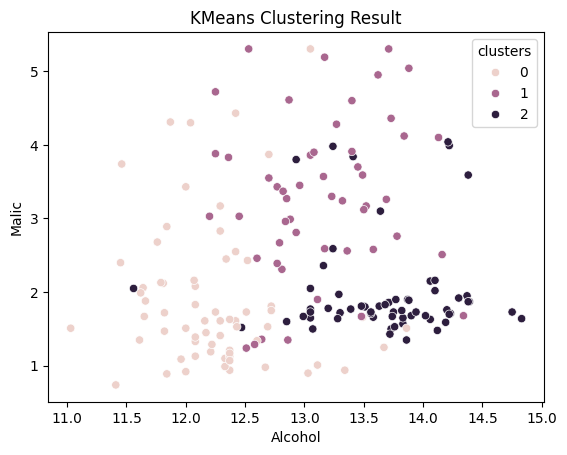

In [80]:
sns.scatterplot(data=df, x='Alcohol', y='Malic', hue='clusters')
plt.title('KMeans Clustering Result')
plt.show()

**3.	Evaluate the clustering performance using metrics such as silhouette score or Davies–Bouldin index.**

In [81]:
silhouette_score(features_std, clusters.labels_)

np.float64(0.2854626783251893)

Explanation:
---

In Task 3, I applied K-Means clustering on the standardized features (features_std) so that all columns are in the same scale and no feature dominates because of high values. I set n_clusters=3 (because the Wine dataset has 3 natural groups/types), trained the model, and generated cluster labels (0,1,2). Then I added these labels into the dataset as a new column to clearly see which row belongs to which cluster. For visualization, I used a scatterplot taking Alcohol (x-axis) and Malic (y-axis) because we can only plot 2 features at a time in a 2D graph, and these 2 columns give a clear view of separation between groups. Finally, I evaluated the clustering performance using Silhouette Score, which tells how well the clusters are separated (your score ~0.28 means clustering is okay but not extremely strong).

# **`Task 4: Clustering with PCA Data:`**


**1.	Apply the same clustering algorithm to the PCA-transformed dataset.**


In [82]:
pca_data = pca.transform(features_std)

In [83]:
kmeans_pca = KMeans(n_clusters=3)
cluster_pca = kmeans_pca.fit(pca_data)

**2.	Visualize the clustering results obtained from PCA-transformed data.**


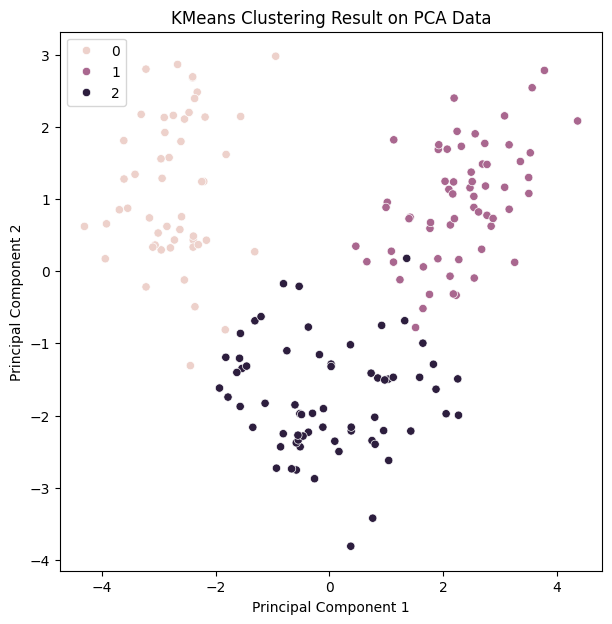

In [84]:
plt.figure(figsize=(7,7))
sns.scatterplot(x=pca_data[:, 0], y=pca_data[:, 1], hue=cluster_pca.labels_)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('KMeans Clustering Result on PCA Data')
plt.show()

**3.	Compare the clustering results from PCA-transformed data with those from the original dataset.**

In [85]:
original_labels = clusters.labels_
pca_labels = cluster_pca.labels_

In [86]:
print("Silhouette Score for Original Data:", silhouette_score(features_std, original_labels))
print("Silhouette Score for PCA Data:", silhouette_score(pca_data, pca_labels))

Silhouette Score for Original Data: 0.2854626783251893
Silhouette Score for PCA Data: 0.30012154914916467


Explanation:
---

In this task, K-Means clustering was applied to the PCA-transformed data instead of the original features. The standardized data was first converted into principal components, and then K-Means with k = 3 was used to generate clusters. The clustering results were visualized using Principal Component 1 vs Principal Component 2, since PCA allows clear 2D visualization. Finally, clustering performance was compared with the original data using Silhouette Score, and the PCA-based clustering showed a slightly better score, indicating improved cluster separation after dimensionality reduction.

# **`Task 5: Comparison and Analysis:`**



**1.	Compare the clustering results obtained from the original dataset and PCA-transformed data.**


In the original dataset, KMeans clustering was applied on the standardized features and we got clusters with some separation. After applying PCA and clustering again, the PCA data gave slightly better separation between clusters. so PCA helped in giving a cleaner cluster structure compared to original data.

**2.	Discuss any similarities or differences observed in the clustering results.**


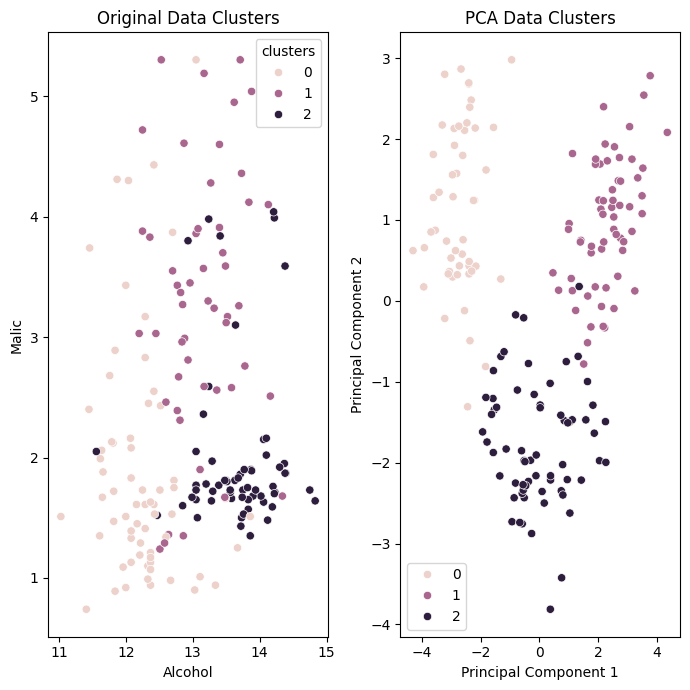

In [87]:
plt.figure(figsize=(7,7))

#original data plot(Alcohol and Malic)
plt.subplot(1,2,1)
sns.scatterplot(data=df, x='Alcohol', y='Malic', hue='clusters')
plt.title('Original Data Clusters')
plt.xlabel('Alcohol')
plt.ylabel('Malic')

#PCA data plot(PCA1 and PCA2)
plt.subplot(1,2,2)
sns.scatterplot(x=pca_data[:,0], y=pca_data[:,1], hue=cluster_pca.labels_)
plt.title('PCA Data Clusters')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.tight_layout( )
plt.show()

I visualized both original and PCA clusters to clearly observe the difference in cluster separation and overlap.

Both Orginial and PCA data created 3 clusters, but the PCA clusters looked more clearly grouped when plotted using prinicipal component 1 & 2. In original data, clusters were slightly better separation between clusters. So PCA helped in giving a cleaner cluster structure compared to original data.

**3.	Reflect on the impact of dimensionality reduction on clustering performance.**


Dimensionality reduction using PCA reduced the noise and combined important information into fewer components. Because of that, clustering became a bit more effective and performance improved slightly. Also visualization became easier with PCA since we can directly see clusters in 2D.

**4.	Analyze the trade-offs between using PCA and clustering directly on the original dataset.**


Using PCA makes clustering faster and simpler, and helps reduce complexity by using fewer features. But the drawback is PCA may lose some small information while compressing the dataset. Clustering on original data keeps full information but it may be harder to interpret and can give more overlap in clusters.

# **`Task 6: Conclusion and Insights:`**



**1.	Summarize the key findings and insights from the assignment.**


    •	We applied PCA to reduce dimensions of Wine dataset.
	•	We used scree plot + cumulative explained variance to choose components.
	•	We applied KMeans clustering on original and PCA data.
	•	PCA clustering gave slightly better cluster separation

**2.	Discuss the practical implications of using PCA and clustering in data analysis.**


	•	PCA helps in reducing dataset complexity.
	•	Makes clustering faster and easier to visualize (PC1 vs PC2).
	•	Useful when dataset has many features.

**3.	Provide recommendations for when to use each technique based on the analysis conducted.**

	•	Use original data clustering when you want full feature interpretation.
	•	Use PCA + clustering when dataset is high-dimensional and you want better separation + faster training.